In [1]:
!pip install fastai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 112.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 91.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 58.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.7/188.7 MB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 103.1 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstal

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from fastai.text.all import *

In [3]:
df = pd.read_csv("filtered_data.csv", usecols=['Normalized_Skills', 'Job Role'])
df.head()

,Job Role,Normalized_Skills
0,AI Researcher,TensorFlow NLP Pytorch
1,Data Scientist,Deep Learning Machine Learning Python SQL
2,Cybersecurity Analyst,Ethical Hacking Cybersecurity Linux
3,AI Researcher,Python Pytorch TensorFlow
4,Software Engineer,SQL React Java


# Split the data
Split dataset into train and vakud **sets**

In [4]:
train_df, valid_df = train_test_split(df, test_size=0.2, random_state=42)

In [5]:
train_df.shape, valid_df.shape

((800, 2), (200, 2))

# Create DataLoaders

Create dataloaders for train and valid sets

In [6]:
dls = TextDataLoaders.from_df(train_df,
                              valid_df=valid_df,
                              text_col='Normalized_Skills',
                              label_col='Job Role',
                              is_lm=False,
                              bs=32)
dls.show_batch()

,text,category
0,xxbos xxmaj deep xxmaj learning xxmaj python xxup sql xxmaj machine xxmaj learning,Data Scientist
1,xxbos xxup sql xxmaj machine xxmaj learning xxmaj deep xxmaj learning xxmaj python,Data Scientist
2,xxbos xxmaj machine xxmaj learning xxmaj python xxmaj deep xxmaj learning xxup sql,Data Scientist
3,xxbos xxmaj python xxmaj machine xxmaj learning xxmaj deep xxmaj learning xxup sql,Data Scientist
4,xxbos xxup sql xxmaj deep xxmaj learning xxmaj python xxmaj machine xxmaj learning,Data Scientist
5,xxbos xxup sql xxmaj machine xxmaj learning xxmaj python xxmaj deep xxmaj learning,Data Scientist
6,xxbos xxup sql xxmaj machine xxmaj learning xxmaj python xxmaj deep xxmaj learning,Data Scientist
7,xxbos xxmaj deep xxmaj learning xxup sql xxmaj python xxmaj machine xxmaj learning,Data Scientist
8,xxbos xxmaj machine xxmaj learning xxup sql xxmaj python xxmaj deep xxmaj learning,Data Scientist


# Train the model

In [7]:
learn = text_classifier_learner(dls, AWD_LSTM, loss_func=CrossEntropyLossFlat(), metrics=[accuracy])

finding appropriate learning rate

In [8]:
import torch
from fastcore.foundation import L
torch.serialization.add_safe_globals([L])

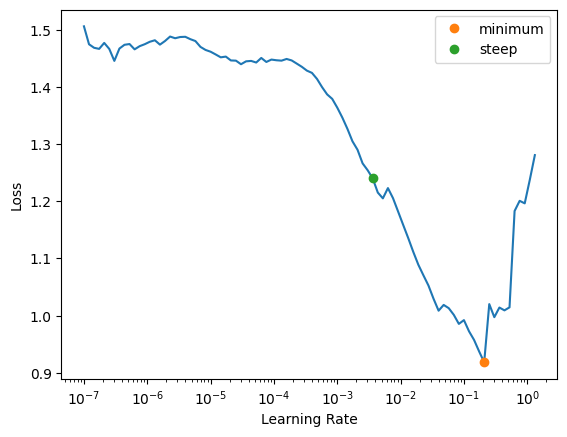

In [9]:
lr_min, lr_steep = learn.lr_find(suggest_funcs=(minimum, steep))

In [10]:
lr_min, lr_steep

(0.02089296132326126, 0.00363078061491251)

- it seems that learning rate 0.03 will be appropriate

In [11]:
learn.fit_one_cycle(8, lr_min)

epoch,train_loss,valid_loss,accuracy,time
0,0.809155,0.232467,0.950000,00:00
1,0.626768,0.096989,0.981250,00:00
2,0.590999,0.094507,0.981250,00:00
3,0.512150,0.030244,0.987500,00:00
4,0.439354,0.022045,1.000000,00:01
5,0.388001,0.025976,0.987500,00:01
6,0.342841,0.022036,0.987500,00:01
7,0.303225,0.020773,0.987500,00:00


# Validate with valid_df
Get predictions and targets

In [12]:
val_preds, val_targets = learn.get_preds()
val_accuracy = accuracy(val_preds, val_targets)
print(f'Validation accuracy: {val_accuracy}')

Validation accuracy: TensorBase(0.9875)


compute classification report

In [13]:
from sklearn.metrics import classification_report, confusion_matrix

In [14]:
classification_report(val_targets, val_preds.argmax(dim=1))

'              precision    recall  f1-score   support\n\n           0       0.96      1.00      0.98        47\n           1       1.00      1.00      1.00        41\n           2       1.00      0.95      0.97        40\n           3       1.00      1.00      1.00        32\n\n    accuracy                           0.99       160\n   macro avg       0.99      0.99      0.99       160\nweighted avg       0.99      0.99      0.99       160\n'

let's see confusion matrix

In [15]:
confusion_matrix(val_targets, val_preds.argmax(dim=1))

array([[47,  0,  0,  0],
       [ 0, 41,  0,  0],
       [ 2,  0, 38,  0],
       [ 0,  0,  0, 32]])

exporting the model

In [17]:
learn.export("resume_model.pkl")

In [18]:
from fastai.text.all import *
learn = load_learner("resume_model.pkl")

/usr/local/lib/python3.11/dist-packages/fastai/learner.py:455: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  warn("load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.\nIf you only need to load model weights and optimizer state, use the safe `Learner.load` instead.")


Using the Model to Predict the Confidence Interval of Resumes

In [20]:
import pandas as pd

# Load resumes dataset
df = pd.read_csv("/content/filtered_data.csv")  # or your filtered_data.csv


In [21]:
from fastai.text.all import *

# Create a test dataloader from your DataFrame
test_dl = learn.dls.test_dl(df['Normalized_Skills'].tolist())

# Get batch predictions
preds, _ = learn.get_preds(dl=test_dl)

# Get predicted label indices & confidence scores
label_idxs = preds.argmax(dim=1)
conf_scores = preds.max(dim=1).values

# Get the category vocabulary from the DataLoaders
category_vocab = learn.dls.vocab[1] # Assuming the second vocabulary list is for labels

# Map indices to labels
labels = [category_vocab[i] for i in label_idxs]

# Add to DataFrame
df['Prediction'] = labels
df['Confidence'] = conf_scores.tolist()

print(df[['Normalized_Skills', 'Prediction', 'Confidence']].head())

                           Normalized_Skills             Prediction  \
0                     TensorFlow NLP Pytorch          AI Researcher   
1  Deep Learning Machine Learning Python SQL         Data Scientist   
2        Ethical Hacking Cybersecurity Linux  Cybersecurity Analyst   
3                  Python Pytorch TensorFlow          AI Researcher   
4                             SQL React Java      Software Engineer   

   Confidence  
0    0.997729  
1    0.970244  
2    0.995259  
3    0.995161  
4    0.983961  


In [22]:
# Add predictions to dataframe
df['Predicted_Category'] = [p[0] for p in preds]
df['Confidence'] = [p[1] for p in preds]


In [23]:
# Sort by confidence (highest first)
df = df.sort_values(by='Confidence', ascending=False)

In [26]:
# Save to Excel
df.to_excel("resume.ranked.xlsx", index=False)

Making The Model to Rank Individual Resumes

In [25]:
pip install python-docx pymupdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.1/24.1 MB 97.2 MB/s eta 0:00:00


In [28]:
from fastai.text.all import *
import docx
import fitz  # PyMuPDF for PDF extraction
import os

# ---------- 1. Load Model ----------
learn = load_learner("resume_model.pkl")

# ---------- 2. File Readers ----------
def read_pdf(file_path):
    text = ""
    with fitz.open(file_path) as pdf:
        for page in pdf:
            text += page.get_text()
    return text.strip()

def read_docx(file_path):
    doc = docx.Document(file_path)
    text = "\n".join([para.text for para in doc.paragraphs])
    return text.strip()

# ---------- 3. Rating Function ----------
def rate_resume_file(file_path):
    # Detect file type
    ext = os.path.splitext(file_path)[1].lower()
    if ext == ".pdf":
        resume_text = read_pdf(file_path)
    elif ext == ".docx":
        resume_text = read_docx(file_path)
    else:
        raise ValueError("Unsupported file type. Use PDF or DOCX.")

    if not resume_text:
        raise ValueError("No text extracted from the resume.")

    # Predict
    pred, pred_idx, probs = learn.predict(resume_text)
    confidence = probs.max().item()

    # Map confidence to stars
    if confidence >= 0.9:
        stars = 5
    elif confidence >= 0.75:
        stars = 4
    elif confidence >= 0.6:
        stars = 3
    elif confidence >= 0.45:
        stars = 2
    else:
        stars = 1

    return {
        "Predicted Category": pred,
        "Confidence": round(confidence, 2),
        "Stars": stars
    }


In [30]:
resume_file = "Enter Your Resume File Here"
result = rate_resume_file(resume_file)

print(f"Predicted Category: {result['Predicted Category']}")
print(f"Confidence: {result['Confidence']}")
print(f"Rating: {'⭐' * result['Stars']}")


Predicted Category: AI Researcher
Confidence: 0.69
Rating: ⭐⭐⭐


In [31]:
import pandas as pd

# Load the ranked resumes file
ranked_df = pd.read_excel("resume.ranked.xlsx")

# Get the count of each predicted job role
predicted_role_counts = ranked_df['Prediction'].value_counts()

print("Distribution of Predicted Job Roles:")
print(predicted_role_counts)

Distribution of Predicted Job Roles:
Prediction
AI Researcher            271
Cybersecurity Analyst    255
Data Scientist           241
Software Engineer        233
Name: count, dtype: int64
